# Hoja de Trabajo 6 — Task 1: equilibrios, estabilidad lineal y predicción
CC2017 Modelación y Simulación · Grupo 3

Sistema: $\dot x = r_1 x(1-x-\alpha_{12}y)$, $\dot y = r_2 y(1-y-\alpha_{21}x)$.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import os; os.makedirs('figs', exist_ok=True)
np.random.seed(0)   # reproducibilidad (el Task 1 es analítico y determinista)

g = 3
conjuntos = {1: (0.5, 0.6), 2: (1.4, 1.5), 3: (0.6, 1.5), 4: (1.5, 0.6)}
conj = ((g - 1) % 4) + 1
a12, a21 = conjuntos[conj]
r1 = 1.0
r2 = 0.5 + 0.1 * ((g - 1) % 5)
print(f"g = {g} | conjunto {conj} | alpha12 = {a12}, alpha21 = {a21} | r1 = {r1}, r2 = {r2:.1f}")

P = {'P1': (0.05, 0.05), 'P2': (0.80, 0.30), 'P3': (0.30, 0.80), 'P4': (0.60, 0.60)}

def campo(x, y, a12=a12, a21=a21, r1=r1, r2=r2):          # lado derecho del sistema
    return r1 * x * (1 - x - a12 * y), r2 * y * (1 - y - a21 * x)

g = 3 | conjunto 3 | alpha12 = 0.6, alpha21 = 1.5 | r1 = 1.0, r2 = 0.7


## Task 1.1

### 1.1a  Equilibrios (a mano)

$\dot x=0 \iff x=0$ o $1-x-\alpha_{12}y=0$; $\dot y=0 \iff y=0$ o $1-y-\alpha_{21}x=0$. Combinando:

* $x=0,\ y=0$: $(0,0)$.
* $x\neq0,\ y=0$: $1-x=0$, es decir $(1,0)$.
* $x=0,\ y\neq0$: $1-y=0$, es decir $(0,1)$.
* $x\neq0,\ y\neq0$: sistema lineal $x+\alpha_{12}y=1$, $\alpha_{21}x+y=1$. Su determinante es $1-\alpha_{12}\alpha_{21}$ y por Cramer

$$x^*=\frac{1-\alpha_{12}}{1-\alpha_{12}\alpha_{21}},\qquad y^*=\frac{1-\alpha_{21}}{1-\alpha_{12}\alpha_{21}}\qquad(\alpha_{12}\alpha_{21}\neq1).$$

### 1.1b  Condición de factibilidad del equilibrio interior

Se necesita $x^*>0$ y $y^*>0$. Con $D=1-\alpha_{12}\alpha_{21}$ (ambos tienen el mismo denominador):

$$x^*y^*=\frac{(1-\alpha_{12})(1-\alpha_{21})}{D^2}.$$

**($\Rightarrow$)** Si $x^*>0$ y $y^*>0$, entonces $x^*y^*>0$, y como $D^2>0$ queda $(1-\alpha_{12})(1-\alpha_{21})>0$. Con ambos distintos de 1, los dos factores tienen el mismo signo: ambos $\alpha<1$ o ambos $\alpha>1$.

**($\Leftarrow$)** Si ambos $\alpha<1$: los numeradores son positivos y $\alpha_{12}\alpha_{21}<1$, o sea $D>0$, así que $x^*,y^*>0$. Si ambos $\alpha>1$: los numeradores son negativos y $\alpha_{12}\alpha_{21}>1$, o sea $D<0$, así que de nuevo $x^*,y^*>0$.

Si uno es menor y el otro mayor que 1, $(1-\alpha_{12})(1-\alpha_{21})<0$ y una de las coordenadas es negativa. $\blacksquare$

Comprobación numérica de la equivalencia sobre una malla de $(\alpha_{12},\alpha_{21})$:

la condición 'ambos <1 o ambos >1' coincide con x*>0 y y*>0 en toda la malla: True


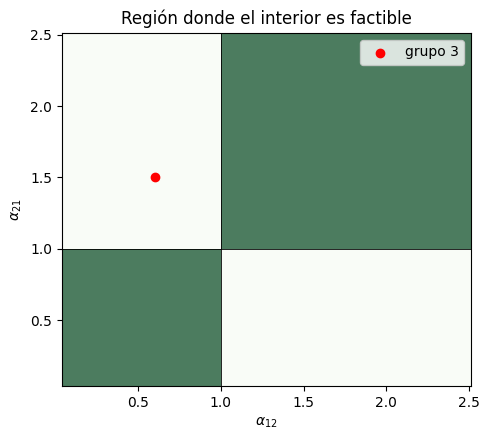

In [2]:
A = np.linspace(0.05, 2.5, 99)                               # malla (se evita alpha = 1 exacto)
A = A[np.abs(A - 1) > 1e-9]
ok = True
for u in A:
    for v in A:
        D = 1 - u * v
        if abs(D) < 1e-9: continue                           # alpha12*alpha21 = 1: no hay interior único
        xs, ys = (1 - u) / D, (1 - v) / D
        factible = (xs > 0) and (ys > 0)
        regla = (u < 1 and v < 1) or (u > 1 and v > 1)
        ok &= (factible == regla)
print("la condición 'ambos <1 o ambos >1' coincide con x*>0 y y*>0 en toda la malla:", ok)

U, V = np.meshgrid(A, A)
Dm = 1 - U * V; Dm[np.abs(Dm) < 1e-9] = np.nan
with np.errstate(invalid='ignore'): Fx = ((1 - U) / Dm > 0) & ((1 - V) / Dm > 0)
plt.figure(figsize=(5, 4.5)); plt.pcolormesh(U, V, Fx, cmap='Greens', shading='auto', alpha=.7)
plt.scatter([a12], [a21], c='r', zorder=5, label='grupo 3'); plt.axvline(1, color='k', lw=.6); plt.axhline(1, color='k', lw=.6)
plt.xlabel(r'$\alpha_{12}$'); plt.ylabel(r'$\alpha_{21}$'); plt.legend(); plt.title('Región donde el interior es factible'); plt.tight_layout()
plt.savefig('figs/t11_factible.png', dpi=150); plt.show()

### 1.1c  Equilibrios con los parámetros del grupo

In [3]:
D = 1 - a12 * a21
xs_, ys_ = (1 - a12) / D, (1 - a21) / D
eqs = {'(0,0)': (0.0, 0.0), '(1,0)': (1.0, 0.0), '(0,1)': (0.0, 1.0), 'interior': (xs_, ys_)}
for n, (x, y) in eqs.items():
    print(f"{n:9s} = ({x:6.3f}, {y:6.3f})  factible: {x >= 0 and y >= 0}   | campo en el punto: {np.round(campo(x, y), 12)}")

(0,0)     = ( 0.000,  0.000)  factible: True   | campo en el punto: [0. 0.]
(1,0)     = ( 1.000,  0.000)  factible: True   | campo en el punto: [ 0. -0.]
(0,1)     = ( 0.000,  1.000)  factible: True   | campo en el punto: [0. 0.]
interior  = ( 4.000, -5.000)  factible: False   | campo en el punto: [ 0. -0.]


Con $\alpha_{12}=0.6<1$ y $\alpha_{21}=1.5>1$ no se cumple la condición del inciso b. El interior es $(4,\,-5)$: no es factible (la coordenada $y$ es negativa). Los otros tres equilibrios están sobre los ejes y son factibles.

## Task 1.2

### 1.2a  Jacobiana

Con $f_1=r_1x(1-x-\alpha_{12}y)$ y $f_2=r_2y(1-y-\alpha_{21}x)$:

$$J=\begin{pmatrix}\partial f_1/\partial x&\partial f_1/\partial y\\ \partial f_2/\partial x&\partial f_2/\partial y\end{pmatrix}=\begin{pmatrix}r_1(1-2x-\alpha_{12}y)&-r_1\alpha_{12}x\\ -r_2\alpha_{21}y&r_2(1-2y-\alpha_{21}x)\end{pmatrix}.$$

SymPy solo verifica la derivada hecha a mano:

In [4]:
import sympy as sp
x, y, A12, A21, R1, R2 = sp.symbols('x y alpha12 alpha21 r1 r2')
F = sp.Matrix([R1*x*(1 - x - A12*y), R2*y*(1 - y - A21*x)])
Jsym = F.jacobian([x, y])
Jmano = sp.Matrix([[R1*(1 - 2*x - A12*y), -R1*A12*x], [-R2*A21*y, R2*(1 - 2*y - A21*x)]])
print("J (SymPy) - J (a mano) =", sp.simplify(Jsym - Jmano).tolist())

# determinante en el interior: Delta = r1 r2 x* y* (1 - a12 a21)   (se usa en el Task 1.4)
xi, yi = (1 - A12)/(1 - A12*A21), (1 - A21)/(1 - A12*A21)
print("Delta interior =", sp.factor(sp.simplify(Jsym.subs({x: xi, y: yi}).det())))

J (SymPy) - J (a mano) = [[0, 0], [0, 0]]
Delta interior = -r1*r2*(alpha12 - 1)*(alpha21 - 1)/(alpha12*alpha21 - 1)


### 1.2b  Clasificación en los equilibrios factibles

Sobre los ejes la jacobiana es triangular y los valores propios son los elementos de la diagonal:

* $(0,0)$: $J=\mathrm{diag}(r_1,r_2)$, $\lambda=r_1=1$ y $r_2=0.7$.
* $(1,0)$: $J=\begin{pmatrix}-r_1&-r_1\alpha_{12}\\0&r_2(1-\alpha_{21})\end{pmatrix}$, $\lambda=-r_1=-1$ y $r_2(1-\alpha_{21})=-0.35$.
* $(0,1)$: $J=\begin{pmatrix}r_1(1-\alpha_{12})&0\\-r_2\alpha_{21}&-r_2\end{pmatrix}$, $\lambda=r_1(1-\alpha_{12})=0.4$ y $-r_2=-0.7$.

In [5]:
def jac(x, y, a12=a12, a21=a21, r1=r1, r2=r2):
    return np.array([[r1 * (1 - 2*x - a12*y), -r1 * a12 * x],
                     [-r2 * a21 * y,           r2 * (1 - 2*y - a21*x)]])

def clasifica(tau, Dt, disc):
    if Dt < 0: return 'silla (inestable)'
    if abs(tau) < 1e-12: return 'centro'
    tipo = 'nodo' if disc >= 0 else 'foco'
    return f"{tipo} {'estable' if tau < 0 else 'inestable'}"

filas = []
for n, (x, y) in eqs.items():
    J = jac(x, y); tau = np.trace(J); Dt = np.linalg.det(J); disc = tau**2 - 4*Dt
    filas.append({'equilibrio': n, 'factible': x >= 0 and y >= 0, 'tau': tau, 'Delta': Dt, 'tau^2-4Delta': disc,
                  'lambda': np.round(np.sort(np.linalg.eigvals(J).real), 4), 'clasificación': clasifica(tau, Dt, disc)})
df = pd.DataFrame(filas); print(df.round(4).to_string(index=False))

# comprobación de los valores propios analíticos de los ejes
print("\nanalíticos: (0,0) ->", sorted([r1, r2]), "| (1,0) ->", sorted([-r1, r2*(1 - a21)]), "| (0,1) ->", sorted([r1*(1 - a12), -r2]))

equilibrio  factible   tau  Delta  tau^2-4Delta            lambda     clasificación
     (0,0)      True  1.70   0.70        0.0900        [0.7, 1.0]    nodo inestable
     (1,0)      True -1.35   0.35        0.4225     [-1.0, -0.35]      nodo estable
     (0,1)      True -0.30  -0.28        1.2100       [-0.7, 0.4] silla (inestable)
  interior     False -0.50  -1.40        5.8500 [-1.4593, 0.9593] silla (inestable)

analíticos: (0,0) -> [0.7, 1.0] | (1,0) -> [-1.0, -0.35] | (0,1) -> [-0.7, 0.4]


### 1.2c  Plano traza-determinante

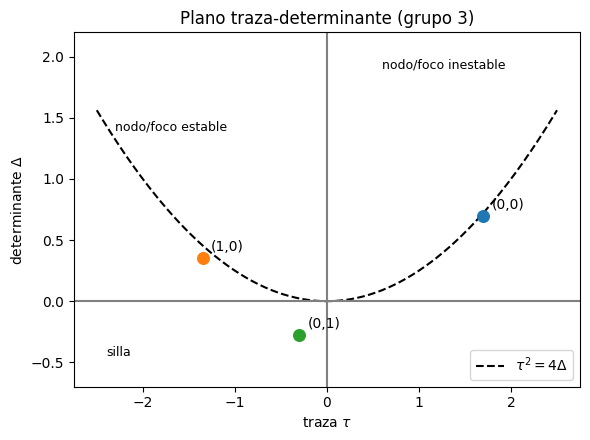

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
t = np.linspace(-2.5, 2.5, 300); ax.plot(t, t**2/4, 'k--', label=r'$\tau^2=4\Delta$')
ax.axhline(0, color='gray'); ax.axvline(0, color='gray')
for _, r in df[df.factible].iterrows():
    ax.scatter(r.tau, r.Delta, s=70, zorder=5); ax.annotate(r.equilibrio, (r.tau, r.Delta), textcoords='offset points', xytext=(6, 5))
ax.text(-2.4, -0.45, 'silla', fontsize=9); ax.text(-2.3, 1.4, 'nodo/foco estable', fontsize=9); ax.text(0.6, 1.9, 'nodo/foco inestable', fontsize=9)
ax.set_xlabel(r'traza $\tau$'); ax.set_ylabel(r'determinante $\Delta$'); ax.set_ylim(-0.7, 2.2); ax.legend(loc='lower right'); ax.set_title('Plano traza-determinante (grupo 3)')
plt.tight_layout(); plt.savefig('figs/t12_traza_det.png', dpi=150); plt.show()

**Posición y sensibilidad.** $(0,1)$ tiene $\Delta=-0.28<0$, está bien dentro de la región de silla; sólo dejaría de serlo si $\alpha_{12}$ subiera hasta 1 (el valor propio $r_1(1-\alpha_{12})$ cruza cero), así que un error pequeño en los parámetros no cambia su clasificación. $(1,0)$ tiene $\tau=-1.35$, $\Delta=0.35>0$ y $\tau^2-4\Delta=0.42>0$: nodo estable, con un margen de 0.5 respecto del cambio $\alpha_{21}=1$ (donde $\Delta\to0$ y pasaría a silla). $(0,0)$ tiene $\tau=1.7$, $\Delta=0.7$ y $\tau^2-4\Delta=0.09>0$: nodo inestable, pero queda muy cerca de la parábola $\tau^2=4\Delta$ porque $r_1$ y $r_2$ son parecidos; aun así los valores propios son reales siempre (la matriz es diagonal en ese punto), así que ni siquiera un cambio de tipo nodo a foco es posible, y lo que sí se mantiene ($\tau>0$, $\Delta>0$) es que es una fuente.

### 1.2d  Régimen

Solo hay un equilibrio estable, $(1,0)$ (nodo con $\lambda=-1$ y $-0.35$). El origen es fuente y $(0,1)$ es silla (inestable en la dirección de $x$). El interior no es factible. El régimen es **exclusión de la plataforma B**: la plataforma A termina con toda la capacidad del mercado y B desaparece.

## Task 1.3

### 1.3a  Nulclinas

* Nulclinas de $x$ ($\dot x=0$): $x=0$ y $x+0.6y=1$, es decir $y=(1-x)/0.6$.
* Nulclinas de $y$ ($\dot y=0$): $y=0$ y $y+1.5x=1$, es decir $y=1-1.5x$.

Las rectas interiores se cortan en $(4,-5)$, fuera del cuadrante. Las intersecciones dentro del cuadrante son $(0,0)$, $(1,0)$ y $(0,1)$.

R1 (bajo ambas)      punto (0.2,0.2): signo(xdot), signo(ydot) = (1, 1)
R2 (entre las dos)   punto (0.5,0.5): signo(xdot), signo(ydot) = (1, -1)
R3 (sobre ambas)     punto (0.2,1.4): signo(xdot), signo(ydot) = (-1, -1)


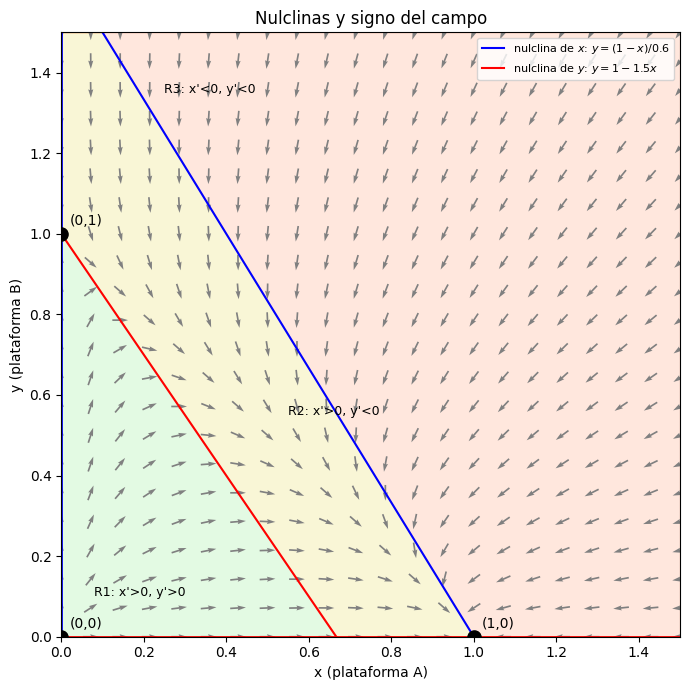

In [7]:
xx = np.linspace(0, 1.5, 300)
L1 = (1 - xx) / a12            # nulclina de x:  y = (1-x)/alpha12
L2 = 1 - a21 * xx              # nulclina de y:  y = 1 - alpha21 x

# 1.3b: signo de xdot, ydot en una muestra de cada región
def region(x, y):
    sx = np.sign(campo(x, y)[0]); sy = np.sign(campo(x, y)[1])
    return int(sx), int(sy)
muestras = {'R1 (bajo ambas)': (0.2, 0.2), 'R2 (entre las dos)': (0.5, 0.5), 'R3 (sobre ambas)': (0.2, 1.4)}
for n, (px, py) in muestras.items():
    print(f"{n:20s} punto ({px},{py}): signo(xdot), signo(ydot) = {region(px, py)}")

X, Y = np.meshgrid(np.linspace(0, 1.5, 22), np.linspace(0, 1.5, 22))
U, Vv = campo(X, Y); N = np.hypot(U, Vv) + 1e-12
fig, ax = plt.subplots(figsize=(7, 7))
ax.fill_between(xx, 0, np.clip(L2, 0, 1.5), color='lightgreen', alpha=.25)
ax.fill_between(xx, np.clip(L2, 0, 1.5), np.clip(L1, 0, 1.5), color='khaki', alpha=.35)
ax.fill_between(xx, np.clip(L1, 0, 1.5), 1.5, color='lightsalmon', alpha=.25)
ax.quiver(X, Y, U / N, Vv / N, pivot='mid', color='gray')
ax.plot(xx, L1, 'b', label=r'nulclina de $x$: $y=(1-x)/0.6$'); ax.plot(xx, L2, 'r', label=r'nulclina de $y$: $y=1-1.5x$')
ax.axvline(0, color='b', lw=2); ax.axhline(0, color='r', lw=2)
ax.text(0.08, 0.1, 'R1: x\'>0, y\'>0', fontsize=9); ax.text(0.55, 0.55, 'R2: x\'>0, y\'<0', fontsize=9); ax.text(0.25, 1.35, 'R3: x\'<0, y\'<0', fontsize=9)
for n, (px, py) in eqs.items():
    if px >= 0 and py >= 0: ax.scatter(px, py, s=90, c='k', zorder=6); ax.annotate(n, (px, py), textcoords='offset points', xytext=(6, 6))
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5); ax.set_xlabel('x (plataforma A)'); ax.set_ylabel('y (plataforma B)'); ax.legend(loc='upper right', fontsize=8)
ax.set_title('Nulclinas y signo del campo'); plt.tight_layout(); plt.savefig('figs/t13_nulclinas.png', dpi=150); plt.show()

**1.3b.** Las dos rectas interiores no se cruzan en el cuadrante y la de $y$ queda siempre debajo de la de $x$. Eso deja tres regiones:

* **R1** (bajo ambas nulclinas): $\dot x>0$ y $\dot y>0$, la flecha apunta arriba-derecha.
* **R2** (entre ellas): $\dot x>0$ y $\dot y<0$, apunta abajo-derecha.
* **R3** (sobre ambas): $\dot x<0$ y $\dot y<0$, apunta abajo-izquierda.

**Ejes.** Si $x=0$ entonces $\dot x=r_1\cdot0\cdot(\dots)=0$, así que el eje $x=0$ es invariante (una plataforma sin usuarios no gana usuarios). Igual con $y=0$: $\dot y=0$. Ambos ejes son invariantes, y dentro de ellos la dinámica es logística.

Cruces entre regiones: sobre la nulclina de $x$ el flujo es vertical hacia abajo (porque $\dot y<0$ ahí), o sea de R3 a R2. Sobre la nulclina de $y$ el flujo es horizontal hacia la derecha, o sea de R1 a R2. Nada sale de R2, y dentro de R2 ambas coordenadas son monótonas.

### 1.3c  Predicciones (no se modifican después de simular)

Todos los puntos terminan en $(1,0)$:

* **P1 (0.05, 0.05):** está en R1 (bajo ambas nulclinas), sale del origen (fuente, $\lambda=1,0.7$) hacia arriba-derecha, cruza la nulclina de $y$ y pasa a R2, donde converge a $(1,0)$.
* **P2 (0.80, 0.30):** en R2 ($y=0.3$ está entre $1-1.5(0.8)<0$ y $(1-0.8)/0.6=0.33$). $x$ crece y $y$ decrece, monótonos y acotados, hacia $(1,0)$.
* **P3 (0.30, 0.80):** en R2 ($0.55<0.8<1.17$). Misma dinámica. Es el más delicado porque está cerca del eje $y$ donde está la silla $(0,1)$, pero con $x_0>0$ no puede llegar a ella: su única variedad estable es el eje $x=0$, que es invariante.
* **P4 (0.60, 0.60):** en R2 ($0.10<0.6<0.67$). Converge a $(1,0)$.

### 1.3d  Tiempo característico de recuperación

El único equilibrio estable es $(1,0)$, con $\lambda=-1$ y $-0.35$. El valor propio más cercano al eje imaginario es $-0.35$:

$$T_{rec}=\frac{1}{\min|\mathrm{Re}\,\lambda|}=\frac{1}{0.35}\approx2.86.$$

In [8]:
lam = np.linalg.eigvals(jac(1, 0)).real
print("valores propios en (1,0):", lam, "| T_rec = 1/min|Re lambda| =", round(1 / np.min(np.abs(lam)), 3))

# Comprobación de las predicciones con un RK4 propio (el Task 2 las analiza con detalle)
def rk4_vec(s, h, T):
    f = lambda z: np.array(campo(z[0], z[1]))
    for _ in range(int(round(T / h))):
        k1 = f(s); k2 = f(s + h/2*k1); k3 = f(s + h/2*k2); k4 = f(s + h*k3); s = s + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return s
for k, s0 in P.items():
    print(k, s0, '->', rk4_vec(np.array(s0), 0.01, 100).round(5))

valores propios en (1,0): [-1.   -0.35] | T_rec = 1/min|Re lambda| = 2.857
P1 (0.05, 0.05) -> [1. 0.]
P2 (0.8, 0.3) -> [1. 0.]


P3 (0.3, 0.8) -> [1. 0.]
P4 (0.6, 0.6) -> [1. 0.]


## Task 1.4  Análisis del compañero ($\alpha_{12}=1.4$, $\alpha_{21}=1.5$, $r_1=1$, $r_2=0.8$)

In [9]:
a4, b4, r24 = 1.4, 1.5, 0.8
d4 = 1 - a4 * b4
xs4, ys4 = (1 - a4) / d4, (1 - b4) / d4
J4 = jac(xs4, ys4, a4, b4, 1.0, r24)
tau4 = np.trace(J4)
D_comp = J4[0,0]*J4[1,1] + J4[0,1]*J4[1,0]          # lo que hizo el compañero (con +)
D_ok = J4[0,0]*J4[1,1] - J4[0,1]*J4[1,0]            # fórmula correcta: Delta = J11 J22 - J12 J21
print("interior:", np.round([xs4, ys4], 4)); print("J =\n", J4.round(3))
print("tau =", round(tau4, 3), "| Delta compañero (+) =", round(D_comp, 3), "| Delta correcto (-) =", round(D_ok, 4))
print("cerrado r1 r2 x* y* (1 - a12 a21) =", round(1 * r24 * xs4 * ys4 * d4, 4), "| np.linalg.det =", round(np.linalg.det(J4), 4))
disc4 = tau4**2 - 4*D_ok
print("tau^2 - 4 Delta =", round(disc4, 4), "| valores propios:", np.linalg.eigvals(J4).round(4), "|", clasifica(tau4, D_ok, disc4))
print("\nequilibrios sobre ejes con estos parámetros:")
for n, (px, py) in {'(1,0)': (1, 0), '(0,1)': (0, 1)}.items():
    Jn = jac(px, py, a4, b4, 1.0, r24); print(n, "lambda =", np.linalg.eigvals(Jn).round(3))

interior: [0.3636 0.4545]
J =
 [[-0.364 -0.509]
 [-0.545 -0.364]]
tau = -0.727 | Delta compañero (+) = 0.41 | Delta correcto (-) = -0.1455
cerrado r1 r2 x* y* (1 - a12 a21) = -0.1455 | np.linalg.det = -0.1455
tau^2 - 4 Delta = 1.1107 | valores propios: [ 0.1633 -0.8906] | silla (inestable)

equilibrios sobre ejes con estos parámetros:
(1,0) lambda = [-1.  -0.4]
(0,1) lambda = [-0.8 -0.4]


**a. Error.** El compañero calculó $\Delta=J_{11}J_{22}+J_{12}J_{21}$. El determinante de una matriz $2\times2$ es $\Delta=J_{11}J_{22}-J_{12}J_{21}$. No es cuestión de criterio: la definición del determinante tiene un signo menos, y es justo ese signo el que decide la clasificación.

**b. Corrección.** $J_{11}J_{22}=(-0.364)(-0.364)=0.132$ y $J_{12}J_{21}=(-0.509)(-0.545)=0.278$, así que

$$\Delta=0.132-0.278\approx-0.146<0.$$

Esto coincide con la fórmula cerrada $\Delta=r_1r_2x^*y^*(1-\alpha_{12}\alpha_{21})=0.8(0.364)(0.455)(-1.1)=-0.146$ (negativa porque $\alpha_{12}\alpha_{21}=2.1>1$). Con $\Delta<0$ el equilibrio interior es una **silla** (inestable): $\tau^2-4\Delta=0.53+0.58>0$ y los valores propios son reales de signo opuesto. Los equilibrios $(1,0)$ y $(0,1)$ son ambos nodos estables ($\lambda=-1,\,-0.4$ y $\lambda=-0.4,\,-0.8$). El régimen es **biestabilidad**: gana quien llegue primero, y la silla interior separa las dos cuencas. No hay coexistencia estable.

**c. Error de interpretación.** Aun si el interior fuera un foco estable, de ahí no se sigue que "el sistema es robusto a perturbaciones". La estabilidad lineal es una propiedad local: dice que perturbaciones pequeñas decaen, pero no dice nada de perturbaciones grandes (depende del tamaño de la cuenca de atracción) ni de la cercanía a una bifurcación (si la parte real de los valores propios está cerca de cero, la recuperación es muy lenta y un error pequeño en los parámetros puede desestabilizar el equilibrio). Además, un foco estable implica oscilaciones amortiguadas que se apagan, no plataformas que "coexisten oscilando". Lo correcto habría sido escribir: "el equilibrio es localmente estable y las perturbaciones pequeñas se recuperan con tiempo característico $1/|\mathrm{Re}\,\lambda|$; su robustez depende de la cuenca y de la distancia a la bifurcación". (En este sistema competitivo, con $J_{12}J_{21}>0$, los valores propios son siempre reales, así que nunca puede haber un foco.)